# VHLSS: xử lý dữ liệu và phân tích

Dữ liệu gồm ba năm 2010, 2012 và 2014. Các phần phân tích hiện dùng hai mẫu độc lập năm 2010 và 2014.

**A. Thu Nhập · B. Chi Tiêu · C. Thu - Chi · D. Tài Sản**

Chạy lần lượt các cell hoặc chọn **Runtime → Run all** trên Colab. Notebook tự tải dữ liệu và lưu bảng đã xử lý vào `processed/vhlss_processed.csv`.

## 1. Thư viện và thông số

Dùng CPI bình quân năm, gốc 2010 = 100; khoảng tin cậy 95% hai phía và mức ý nghĩa 5%.

Nguồn CPI: [Niên giám thống kê 2014, bảng 250, trang 551](https://www.nso.gov.vn/wp-content/uploads/2019/10/Nien-giam-2014-pdf.pdf).

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

CONFIDENCE_LEVEL = 0.95
ALPHA = 1 - CONFIDENCE_LEVEL
CPI = {2010: 100.00, 2012: 129.50, 2014: 143.69}
ANALYSIS_YEARS = [2010, 2014]
TOP_FRACTION = 0.001

OUTPUT_DIR = Path.cwd() / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(pd.Series(CPI, name="CPI · 2010 = 100").rename_axis("year").to_frame())

,CPI · 2010 = 100
year,
2010,100.000
2012,129.500
2014,143.690


## 2. Đọc dữ liệu

Dùng `vhlss_merged.csv` tại một commit cố định để cả nhóm đọc cùng bản. Hash kiểm tra file có khớp nguồn không. Nếu đã tải file về máy, đặt đường dẫn ở `SOURCE_PATH`.

In [2]:
SOURCE_COMMIT = "4a2c3c06ba191010f536b811deb9e65de6424d46"
SOURCE_URL = (
    "https://raw.githubusercontent.com/letranggaby-cloud/vhlss-project-thong-ke/"
    f"{SOURCE_COMMIT}/processed/vhlss_merged.csv"
)
SOURCE_SHA256 = "3bd8aa79bea915a588ff7340b24020d66369fd6024e5af1f9670fad59b09bd6d"
SOURCE_PATH = None  # Điền đường dẫn nếu dùng file tải lên.

if SOURCE_PATH is None:
    with urlopen(SOURCE_URL, timeout=90) as response:
        source_bytes = response.read()
else:
    source_bytes = Path(SOURCE_PATH).read_bytes()

if hashlib.sha256(source_bytes).hexdigest() != SOURCE_SHA256:
    raise ValueError("File không khớp bản nguồn. Kiểm tra lại đường dẫn.")

raw = pd.read_csv(BytesIO(source_bytes))
print(f"Đầu vào: {len(raw):,} dòng × {raw.shape[1]} cột.")
display(raw.head(3))

Đầu vào: 28,196 dòng × 31 cột.


,Year,province,area,size,income,rice,...,tv,emachine,hmachine,Inc_head,Quart,year
0,2010,1,1,6,"146,800.000","4,613.000",...,"16,000.000",500.000,"16,150.000","24,466.667",4,2010
1,2010,1,1,2,"268,300.000","2,358.500",...,"5,000.000",500.000,"34,800.000","134,150.000",4,2010
2,2010,1,1,4,"279,400.000","3,952.500",...,500.000,0.000,"7,200.000","69,850.000",4,2010


## 3. Làm sạch và tạo biến

- Giữ tất cả dòng và nhãn Quart gốc. Chưa có mã hộ để xác nhận các dòng giống nhau là trùng hộ.
- Tiền âm hoặc không hợp lệ chuyển thành thiếu; số 0 giữ nguyên. Không điền ô thiếu bằng 0.
- Thu nhập và các khoản chi có đơn vị nghìn đồng/hộ/năm. Nhà và đồ bền là giá trị tài sản tại khảo sát.
- Tổng chi 13 khoản cần đủ cả 13. Tính thêm tổng 12 khoản, không gồm `fuel`, để đối chiếu.
- Tài sản > 0 là có sở hữu, = 0 là không; thiếu là chưa rõ. Chi điện/nước/rác chỉ đo mức chi.

In [3]:
EXPENSE_COLUMNS = [
    "rice", "nrice", "tobaco", "nfood", "edu", "med", "hins",
    "aid", "water", "elec", "garb", "fuel", "fhouse",
]
ASSET_COLUMNS = [
    "house", "oto", "moto", "bicycle", "bed", "tab", "tele", "tv", "emachine", "hmachine",
]
MONEY_COLUMNS = ["income", *EXPENSE_COLUMNS, *ASSET_COLUMNS]
PROVINCE_CODES = [
    1, 2, 4, 6, 8, 10, 11, 12, 14, 15, 17, 19, 20, 22, 24, 25,
    26, 27, 30, 31, 33, 34, 35, 36, 37, 38, 40, 42, 44, 45, 46,
    48, 49, 51, 52, 54, 56, 58, 60, 62, 64, 66, 67, 68, 70, 72,
    74, 75, 77, 79, 80, 82, 83, 84, 86, 87, 89, 91, 92, 93, 94, 95, 96,
]

### 3.1. Tên cột và kiểu dữ liệu

Gộp `Year/year` nếu hai cột khớp nhau; đổi các cột số về cùng kiểu.

In [4]:
data = raw.copy()
data.columns = data.columns.str.strip().str.lower()
data = data.rename(columns={"tabl": "tab", "inc_head": "income_pc_reported"})

# Nguồn hiện có cả Year và year; chỉ giữ một cột khi hai cột khớp.
if list(data.columns).count("year") > 1:
    year_columns = data.loc[:, "year"]
    if not year_columns.eq(year_columns.iloc[:, 0], axis=0).all().all():
        raise ValueError("Hai cột năm không khớp.")
    data = data.loc[:, ~data.columns.duplicated()].copy()
if data.columns.duplicated().any():
    raise ValueError("Còn tên cột bị trùng sau chuẩn hóa.")

required = ["year", "province", "area", "size", "quart", "income_pc_reported", *MONEY_COLUMNS]
absent = set(required) - set(data.columns)
if absent:
    raise ValueError(f"Thiếu cột bắt buộc: {sorted(absent)}")

audit_rows = []
for column in required:
    original = data[column]
    numeric = pd.to_numeric(original, errors="coerce")
    finite = numeric.where(np.isfinite(numeric))
    audit_rows.append({
        "variable": column, "missing_input": int(original.isna().sum()),
        "invalid_numeric": int((original.notna() & finite.isna()).sum()),
        "negative": int(finite.lt(0).sum()),
    })
    data[column] = finite

### 3.2. Mã nhóm và giá trị thiếu

Giữ mã hợp lệ cho tỉnh, khu vực, Quart; quy mô hộ phải là số nguyên dương. `record_id` chỉ dùng truy ngược dòng, không dùng ghép hộ giữa các năm.

In [5]:
if data["year"].isna().any() or not data["year"].isin(CPI).all():
    raise ValueError("Có năm thiếu hoặc chưa khai báo CPI.")
data["year"] = data["year"].astype(int)
data.insert(0, "source_row", np.arange(len(data)) + 2)  # Dòng trong CSV, không phải mã hộ.
data.insert(0, "record_id", data["year"].astype(str) + "-" + data["source_row"].astype(str))

for column, valid_codes in [("province", PROVINCE_CODES), ("area", [1, 2]), ("quart", [1, 2, 3, 4])]:
    data[column] = data[column].where(data[column].isin(valid_codes)).astype("Int64")
data["size"] = data["size"].where(data["size"].gt(0) & data["size"].mod(1).eq(0))

amount_columns = [*MONEY_COLUMNS, "income_pc_reported"]
data["invalid_amount_count"] = data[amount_columns].lt(0).sum(axis=1)
data[amount_columns] = data[amount_columns].where(data[amount_columns].ge(0))
data["cpi_2010_100"] = data["year"].map(CPI)
price_factor = 100 / data["cpi_2010_100"]

### 3.3. Quy đổi CPI

Tiền giá 2010 = tiền danh nghĩa × 100/CPI. Thu nhập đầu người tính lại từ `income/size`; giữ số nguồn ở `income_pc_reported` để đối chiếu.

In [6]:
# Tiền theo hộ: nghìn đồng; biến đầu người bên dưới: triệu đồng.
real_amounts = data[MONEY_COLUMNS].mul(price_factor, axis=0).add_suffix("_real_2010")
data = pd.concat([data, real_amounts], axis=1)
data["income_pc_nominal"] = data["income"] / data["size"] / 1000
data["income_pc_real"] = data["income_pc_nominal"] * price_factor
data["income_pc_source_mismatch"] = (
    data["income_pc_reported"].notna() & data["income_pc_nominal"].notna()
    & ~np.isclose(data["income_pc_reported"], data["income_pc_nominal"] * 1000)
)

### 3.4. Chi tiêu và tỷ trọng

Chỉ cộng khi đủ thành phần. Các biến `*_pc_real` có đơn vị triệu đồng/người/năm, giá 2010.

In [7]:
data["expense_complete_13"] = data[EXPENSE_COLUMNS].notna().all(axis=1)
expenses_12 = [column for column in EXPENSE_COLUMNS if column != "fuel"]
data["expense_complete_12"] = data[expenses_12].notna().all(axis=1)
data["expense_13_nominal"] = data[EXPENSE_COLUMNS].sum(axis=1, min_count=13)
data["expense_12_nominal"] = data[expenses_12].sum(axis=1, min_count=12)
data["expense_13_pc_real"] = data["expense_13_nominal"] / data["size"] / 1000 * price_factor
data["expense_12_pc_real"] = data["expense_12_nominal"] / data["size"] / 1000 * price_factor
for column in EXPENSE_COLUMNS:
    data[f"{column}_pc_real"] = data[f"{column}_real_2010"] / data["size"] / 1000
data["health_pc_real"] = data[["med_pc_real", "hins_pc_real", "aid_pc_real"]].sum(axis=1, min_count=3)
denominator = data["expense_13_nominal"].where(data["expense_13_nominal"].gt(0))
data["food_share"] = data[["rice", "nrice"]].sum(axis=1, min_count=2) / denominator
data["education_share"] = data["edu"] / denominator

### 3.5. Sở hữu và bảng kiểm tra

In [8]:
for column in ASSET_COLUMNS:
    data[f"owns_{column}"] = data[column].gt(0).where(data[column].notna()).astype("Int64")
data["area_label"] = data["area"].map({1: "Thành thị", 2: "Nông thôn"})
data["quart_label"] = data["quart"].map({q: f"Q{q}" for q in [1, 2, 3, 4]})
cleaning_audit = pd.DataFrame(audit_rows).set_index("variable")
cleaning_audit["missing_output"] = data[cleaning_audit.index].isna().sum()
changed_columns = cleaning_audit.gt(0).any(axis=1)
display(cleaning_audit.loc[changed_columns])

,missing_input,invalid_numeric,negative,missing_output
variable,,,,
nfood,1,0,0,1
fuel,817,0,0,817
fhouse,23,0,0,23
house,23,0,11,34
oto,284,0,0,284
moto,284,0,5,289
bicycle,284,0,3,287
bed,284,0,16,300
tab,284,0,5,289


### 3.6. Kiểm tra và lưu dữ liệu

Xem số dòng hợp lệ và tỷ lệ thiếu theo năm, Quart, khu vực. Mỗi phân tích chỉ bỏ thiếu ở các biến cần dùng.

In [9]:
sample_audit = data.groupby("year").agg(
    households=("record_id", "size"), valid_income=("income_pc_real", "count"),
    complete_13=("expense_complete_13", "sum"), complete_12=("expense_complete_12", "sum"),
    income_mismatch=("income_pc_source_mismatch", "sum"),
)
display(sample_audit)

missing_by_group = data.groupby(["year", "quart_label", "area_label"], dropna=False).agg(
    households=("record_id", "size"), missing_fuel_pct=("fuel", lambda x: 100 * x.isna().mean()),
    missing_expense_13_pct=("expense_13_pc_real", lambda x: 100 * x.isna().mean()),
    missing_moto_pct=("owns_moto", lambda x: 100 * x.isna().mean()),
)
display(missing_by_group.round(2))

assert len(data) == len(raw) and data["record_id"].is_unique
assert set(data["year"]) == set(CPI)
assert data.loc[~data["expense_complete_13"], "expense_13_nominal"].isna().all()
assert data[MONEY_COLUMNS].ge(0).where(data[MONEY_COLUMNS].notna(), True).all().all()
assert data.loc[data["year"].eq(2010), "cpi_2010_100"].eq(100).all()

processed_path = OUTPUT_DIR / "vhlss_processed.csv"
data.to_csv(processed_path, index=False)
print(f"{len(data):,} dòng × {data.shape[1]} cột → processed/{processed_path.name}")
print(f"Nguồn có {raw.duplicated().sum()} dòng giống dòng trước; giữ lại vì chưa có mã hộ xác nhận trùng.")

,households,valid_income,complete_13,complete_12,income_mismatch
year,,,,,
2010,9399,9399,9387,9390,0
2012,9399,9399,9391,9391,0
2014,9398,9398,8579,9391,0


households  missing_fuel_pct  \
year quart_label area_label                                 
2010 Q1          Nông thôn         2155             0.000   
                 Thành thị          195             0.000   
     Q2          Nông thôn         1913             0.000   
                 Thành thị          436             0.000   
     Q3          Nông thôn         1584             0.060   
                 Thành thị          766             0.130   
     Q4          Nông thôn         1098             0.000   
                 Thành thị         1252             0.080   
2012 Q1          Nông thôn         2145             0.050   
                 Thành thị          205             0.000   
     Q2          Nông thôn         1893             0.000   
                 Thành thị          456             0.000   
     Q3          Nông thôn         1557             0.000   
                 Thành thị          793             0.000   
     Q4          Nông thôn         1101             0.000   
                 Thành thị         1249             0.000   
2014 Q1          Nông thôn         2144            21.830   
                 Thành thị          208            18.270   
     Q2          Nông thôn         1882             9.090   
                 Thành thị          468             6.200   
     Q3          Nông thôn         1481             4.320   
                 Thành thị          866             1.150   
     Q4          Nông thôn         1110             1.890   
                 Thành thị         1239             0.970   

                             missing_expense_13_pct  missing_moto_pct  
year quart_label area_label                                            
2010 Q1          Nông thôn                    0.140             5.850  
                 Thành thị                    0.510             5.640  
     Q2          Nông thôn                    0.100             0.890  
                 Thành thị                    0.000             1.610  
     Q3          Nông thôn                    0.130             0.510  
                 Thành thị                    0.130             0.650  
     Q4          Nông thôn                    0.180             0.270  
                 Thành thị                    0.080             0.320  
2012 Q1          Nông thôn                    0.140             2.280  
                 Thành thị                    0.000             2.930  
     Q2          Nông thôn                    0.000             0.110  
                 Thành thị                    0.220             0.000  
     Q3          Nông thôn                    0.000             0.320  
                 Thành thị                    0.130             0.000  
     Q4          Nông thôn                    0.090             0.090  
                 Thành thị                    0.160             0.000  
2014 Q1          Nông thôn                   21.880             1.820  
                 Thành thị                   18.270             0.480  
     Q2          Nông thôn                    9.140             0.110  
                 Thành thị                    6.200             0.000  
     Q3          Nông thôn                    4.390             0.140  
                 Thành thị                    1.150             0.000  
     Q4          Nông thôn                    2.160             0.000  
                 Thành thị                    0.970             0.080

28,196 dòng × 95 cột → processed/vhlss_processed.csv
Nguồn có 9 dòng giống dòng trước; giữ lại vì chưa có mã hộ xác nhận trùng.


### Ký hiệu các biến

| Biến / hậu tố | Ý nghĩa và đơn vị |
|---|---|
| `year`, `province`, `area`, `size`, `quart` | Năm, mã tỉnh giai đoạn khảo sát, khu vực, số người, Quart nguồn |
| `income`, 13 biến chi, 10 biến tài sản | Danh nghĩa, nghìn đồng/hộ; thu/chi tính năm, tài sản là giá trị tại khảo sát |
| `*_real_2010` | Giá 2010, nghìn đồng/hộ; CPI chung cũng chỉ là xấp xỉ cho giá trị tài sản |
| `income_pc_nominal` | Triệu đồng/người/năm, giá hiện hành |
| `income_pc_real`, `*_pc_real` | Triệu đồng/người/năm, giá 2010 |
| `expense_13_*`, `expense_12_*` | Tổng đủ 13 khoản; tổng đối chiếu 12 khoản không gồm fuel |
| `health_pc_real` | Tổng `med + hins + aid` đầu người; cần đủ ba khoản |
| `food_share`, `education_share` | Tỷ trọng trong tổng chi đủ 13 khoản; thang 0–1 |
| `owns_*` | 1 có, 0 không, ô trống chưa rõ |
| `source_row`, `record_id` | Truy ngược dòng CSV nguồn; **không phải mã hộ qua các năm** |
| `income_pc_reported` | Thu nhập đầu người nguồn, nghìn đồng/người/năm |

`rice`: gạo; `nrice`: thực phẩm ngoài gạo; `tobaco`: thuốc lá; `nfood`: phi thực phẩm, chưa gồm khoản chi riêng; `edu`: giáo dục; `med`: thuốc; `hins`: bảo hiểm y tế; `aid`: chăm sóc người bệnh; `water/elec/garb/fuel`: nước/điện/rác/nhiên liệu; `fhouse`: sửa nhà.

`house`: nhà; `oto/moto/bicycle`: ô tô/xe máy/xe đạp; `bed/tab`: giường/bàn ghế; `tele/tv`: điện thoại/tivi; `emachine/hmachine`: thiết bị giải trí/gia dụng.

## 4. Các hàm kiểm định

`x - y` luôn là hướng chênh lệch. `alternative`: `greater` cho H₁ >, `less` cho H₁ <, `two-sided` cho H₁ ≠. H₀ dùng dấu **=**. Các hàm dùng chung `CONFIDENCE_LEVEL` và `ALPHA` ở đầu notebook.

| Nhóm hàm | Kiến thức lớp và điều kiện chính |
|---|---|
| `one_sample_t_test`, `one_sample_z_test` | Chap 6: mean; t khi σ chưa biết, Z khi biết σ tổng thể |
| `paired_t_test` | Chap 7 §7.2.1: hiệu trong cặp thật; cần chuẩn của hiệu hoặc xấp xỉ mean phù hợp |
| `independent_t_test` | Chap 7 §7.2.3–4: hai mẫu độc lập; mặc định Welch, chỉ pooled khi có cơ sở σ₁² = σ₂² |
| `independent_z_test` | Chap 7 §7.2.2: biết cả hai σ tổng thể |
| `variance_test`, `variance_ratio_test` | Chap 6/7 §7.3: χ² một phương sai, F hai phương sai; đòi hỏi tổng thể chuẩn |
| `one_proportion_test`, `two_proportion_test` | Chap 6/7 §7.4: Z tỷ lệ, số thành công/thất bại đủ lớn; hai mẫu độc lập |
| `one_way_anova`, `two_way_anova` | Chap 8: quan sát độc lập, sai số chuẩn và phương sai chung; hàm hai nhân tố chỉ dùng thiết kế cân bằng trong slide |
| `chi_square_gof`, `chi_square_independence` | Chap 9 §9.1–2: tần số đếm, kỳ vọng mỗi ô ≥ 5 |
| `correlation_test` | Chap 7 §7.5/Chap 9 §9.3: Pearson hoặc Spearman; quan sát theo cặp, độc lập giữa các cặp |
| `jarque_bera_test` | Chap 9 §9.4: kiểm tra chuẩn bằng skew/kurtosis, xấp xỉ χ²₂ |

ANOVA mặc định chỉ trả bảng phân rã SS. Chỉ đặt `assumptions_met=True` khi có cơ sở dùng phân phối F.

In [10]:
def numeric_sample(values, minimum=2):
    """Lấy các quan sát hợp lệ của một mẫu."""
    sample = np.asarray(values, dtype=float)
    if sample.ndim != 1:
        raise ValueError("Mẫu phải là mảng một chiều.")
    sample = sample[np.isfinite(sample)]
    if len(sample) < minimum:
        raise ValueError(f"Cần ít nhất {minimum} quan sát hợp lệ.")
    return sample


def paired_samples(x, y, minimum=3):
    """Bỏ thiếu theo cặp."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or x.shape != y.shape:
        raise ValueError("Hai mẫu phải một chiều và cùng độ dài, đã ghép đúng ID.")
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < minimum:
        raise ValueError(f"Cần ít nhất {minimum} cặp hợp lệ.")
    return x[valid], y[valid]

In [11]:
def tail_probability(statistic, distribution, alternative):
    if alternative == "greater":
        return float(distribution.sf(statistic))
    if alternative == "less":
        return float(distribution.cdf(statistic))
    if alternative == "two-sided":
        return float(min(1, 2 * min(distribution.cdf(statistic), distribution.sf(statistic))))
    raise ValueError("alternative phải là greater, less hoặc two-sided.")


def test_result(method, statistic, p_value, **details):
    """Gom kết quả vào một dict."""
    return {"method": method, "statistic": float(statistic), "p_value": float(p_value),
            "reject_h0": bool(p_value < ALPHA), **details}


def mean_test_result(method, estimate, null_value, se, distribution, alternative, **details):
    if not np.isfinite(se) or se <= 0:
        raise ValueError("SE phải dương; kiểm tra mẫu có phương sai bằng 0.")
    statistic = (estimate - null_value) / se
    margin = distribution.ppf(1 - ALPHA / 2) * se
    return test_result(method, statistic, tail_probability(statistic, distribution, alternative),
                       estimate=float(estimate), se=float(se), null_value=null_value,
                       ci_low=float(estimate - margin), ci_high=float(estimate + margin),
                       confidence_level=CONFIDENCE_LEVEL, alternative=alternative, **details)

### 4.1. Mean: t-test và Z-test

Một mẫu: $T=(\bar x-\mu_0)/(s/\sqrt n)$, df = n−1. Mẫu ghép: áp dụng công thức đó lên $d_i=x_i-y_i$.

Hai mẫu độc lập, Welch: $SE=\sqrt{s_x^2/n_x+s_y^2/n_y}$; $\nu=(a+b)^2/[a^2/(n_x-1)+b^2/(n_y-1)]$, với $a=s_x^2/n_x$, $b=s_y^2/n_y$. Bản pooled dùng $s_p^2=[(n_x-1)s_x^2+(n_y-1)s_y^2]/(n_x+n_y-2)$.

CI chênh lệch mean: $(\bar x-\bar y)\pm t_{\nu;0,975}SE$. Z thay phương sai mẫu bằng **phương sai tổng thể đã biết**, dùng chuẩn tắc và mốc 0,975.

In [12]:
def one_sample_t_test(x, mu0=0, alternative="two-sided"):
    x = numeric_sample(x)
    return mean_test_result("One-sample t", x.mean(), mu0, x.std(ddof=1) / np.sqrt(len(x)),
                            stats.t(len(x) - 1), alternative, n=len(x), df=len(x) - 1)


def paired_t_test(x, y, difference0=0, alternative="two-sided"):
    """Chỉ dùng khi x[i], y[i] là cùng đối tượng đã ghép đúng mã."""
    x, y = paired_samples(x, y, minimum=2)
    result = one_sample_t_test(x - y, difference0, alternative)
    return {**result, "method": "Paired t"}

In [13]:
def independent_t_test(x, y, difference0=0, alternative="two-sided", equal_var=False):
    x, y = numeric_sample(x), numeric_sample(y)
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    if equal_var:
        df = nx + ny - 2
        pooled_variance = ((nx - 1) * vx + (ny - 1) * vy) / df
        se = np.sqrt(pooled_variance * (1 / nx + 1 / ny))
    else:
        a, b = vx / nx, vy / ny
        if a + b <= 0:
            raise ValueError("Không tính được Welch khi cả hai phương sai bằng 0.")
        se = np.sqrt(a + b)
        df = (a + b)**2 / (a**2 / (nx - 1) + b**2 / (ny - 1))
    return mean_test_result("Pooled t" if equal_var else "Welch t", x.mean() - y.mean(),
                            difference0, se, stats.t(df), alternative, df=df,
                            n_x=nx, n_y=ny, mean_x=x.mean(), mean_y=y.mean())

In [14]:
def one_sample_z_test(x, sigma, mu0=0, alternative="two-sided"):
    x = numeric_sample(x)
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma tổng thể phải dương.")
    return mean_test_result("One-sample Z", x.mean(), mu0, sigma / np.sqrt(len(x)),
                            stats.norm(), alternative, n=len(x))


def independent_z_test(x, y, sigma_x, sigma_y, difference0=0, alternative="two-sided"):
    x, y = numeric_sample(x), numeric_sample(y)
    if not np.isfinite([sigma_x, sigma_y]).all() or min(sigma_x, sigma_y) <= 0:
        raise ValueError("Cả hai sigma tổng thể phải dương.")
    se = np.sqrt(sigma_x**2 / len(x) + sigma_y**2 / len(y))
    return mean_test_result("Independent Z", x.mean() - y.mean(), difference0, se,
                            stats.norm(), alternative, n_x=len(x), n_y=len(y))

### 4.2. Phương sai và tỷ lệ

Chuẩn: $Q=(n-1)s^2/\sigma_0^2\sim\chi^2_{n-1}$; hai mẫu chuẩn độc lập: $F=(s_x^2/s_y^2)/r_0\sim F_{n_x-1,n_y-1}$. CI của phương sai hoặc tỷ số dùng các phân vị χ²/F tương ứng.

Tỷ lệ: $Z=(\hat p-p_0)/\sqrt{p_0(1-p_0)/n}$. Hai mẫu, H₀: $p_x=p_y$, dùng tỷ lệ gộp trong SE kiểm định; CI chênh lệch dùng SE không gộp. CI tỷ lệ ở đây là **xấp xỉ Wald trong lớp**.

In [15]:
def variance_test(x, variance0, alternative="two-sided", *, normal_population=False):
    if not normal_population:
        raise ValueError("Kiểm định này cần tổng thể chuẩn; xác nhận normal_population=True khi có cơ sở.")
    x = numeric_sample(x)
    if not np.isfinite(variance0) or variance0 <= 0 or x.var(ddof=1) <= 0:
        raise ValueError("Phương sai giả thuyết và phương sai mẫu phải dương.")
    df = len(x) - 1
    numerator = df * x.var(ddof=1)
    statistic = numerator / variance0
    return test_result("Variance chi-square", statistic,
                       tail_probability(statistic, stats.chi2(df), alternative),
                       estimate=x.var(ddof=1), df=df,
                       ci_low=numerator / stats.chi2.ppf(1 - ALPHA / 2, df),
                       ci_high=numerator / stats.chi2.ppf(ALPHA / 2, df),
                       confidence_level=CONFIDENCE_LEVEL)


def variance_ratio_test(x, y, ratio0=1, alternative="two-sided", *, normal_population=False):
    if not normal_population:
        raise ValueError("F-test cần hai tổng thể chuẩn độc lập; xác nhận normal_population=True khi có cơ sở.")
    x, y = numeric_sample(x), numeric_sample(y)
    if not np.isfinite(ratio0) or ratio0 <= 0 or min(x.var(ddof=1), y.var(ddof=1)) <= 0:
        raise ValueError("Tỷ số giả thuyết và hai phương sai mẫu phải dương.")
    ratio = x.var(ddof=1) / y.var(ddof=1)
    distribution = stats.f(len(x) - 1, len(y) - 1)
    return test_result("Variance ratio F", ratio / ratio0,
                       tail_probability(ratio / ratio0, distribution, alternative), estimate=ratio,
                       df1=len(x) - 1, df2=len(y) - 1,
                       ci_low=ratio / distribution.ppf(1 - ALPHA / 2),
                       ci_high=ratio / distribution.ppf(ALPHA / 2), confidence_level=CONFIDENCE_LEVEL)

In [16]:
def validate_counts(successes, n):
    if not np.isfinite([successes, n]).all() or n <= 0 or n != int(n):
        raise ValueError("n phải là số nguyên dương.")
    if successes != int(successes) or not 0 <= successes <= n:
        raise ValueError("Số thành công phải nguyên và nằm trong [0, n].")


def one_proportion_test(successes, n, p0, alternative="two-sided"):
    validate_counts(successes, n)
    if not 0 < p0 < 1 or min(n * p0, n * (1 - p0), successes, n - successes) < 5:
        raise ValueError("Chưa đủ số thành công/thất bại cho Z và CI Wald; không dùng xấp xỉ này.")
    estimate = successes / n
    se_null = np.sqrt(p0 * (1 - p0) / n)
    statistic = (estimate - p0) / se_null
    margin = stats.norm.ppf(1 - ALPHA / 2) * np.sqrt(estimate * (1 - estimate) / n)
    return test_result("One-proportion Z", statistic,
                       tail_probability(statistic, stats.norm(), alternative), estimate=estimate,
                       ci_low=estimate - margin, ci_high=estimate + margin,
                       confidence_level=CONFIDENCE_LEVEL, n=n)


def two_proportion_test(success_x, n_x, success_y, n_y, alternative="two-sided"):
    """H0: p_x - p_y = 0; mỗi success/n tính trên các dòng đã biết trạng thái."""
    validate_counts(success_x, n_x)
    validate_counts(success_y, n_y)
    if min(success_x, n_x - success_x, success_y, n_y - success_y) < 5:
        raise ValueError("Mỗi mẫu cần ít nhất 5 thành công và 5 thất bại.")
    px, py = success_x / n_x, success_y / n_y
    pooled = (success_x + success_y) / (n_x + n_y)
    se_null = np.sqrt(pooled * (1 - pooled) * (1 / n_x + 1 / n_y))
    statistic = (px - py) / se_null
    se_ci = np.sqrt(px * (1 - px) / n_x + py * (1 - py) / n_y)
    margin = stats.norm.ppf(1 - ALPHA / 2) * se_ci
    return test_result("Two-proportion Z", statistic,
                       tail_probability(statistic, stats.norm(), alternative), estimate=px - py,
                       ci_low=px - py - margin, ci_high=px - py + margin,
                       confidence_level=CONFIDENCE_LEVEL, n_x=n_x, n_y=n_y)

### 4.3. ANOVA: có bảng SS, df, MS, F

Một nhân tố: $SS_B=\sum n_g(\bar y_g-\bar y)^2$; $SS_W=\sum_g\sum_i(y_{ig}-\bar y_g)^2$. $F=MS_B/MS_W$; dưới điều kiện ANOVA, $F\sim F_{k-1,N-k}$.

Hai nhân tố: dữ liệu **cân bằng**, mỗi ô có cùng số quan sát; phân rã $SS_T=SS_A+SS_B+SS_{AB}+SS_E$. Với mô hình không tương tác, $SS_{AB}$ được đưa vào phần dư theo giả định cộng tính. Thiết kế không cân bằng sẽ báo lỗi để tránh áp dụng sai công thức slide.

In [17]:
def one_way_anova(groups, *, assumptions_met=False):
    """groups: dict tên nhóm -> mảng số. Mặc định chỉ mô tả SS."""
    samples = {name: numeric_sample(values) for name, values in groups.items()}
    if len(samples) < 2:
        raise ValueError("ANOVA cần ít nhất hai nhóm.")
    sizes = np.array([len(x) for x in samples.values()])
    means = np.array([x.mean() for x in samples.values()])
    grand_mean = np.average(means, weights=sizes)
    ss_between = np.sum(sizes * (means - grand_mean)**2)
    ss_within = sum(np.sum((x - x.mean())**2) for x in samples.values())
    df_between, df_within = len(samples) - 1, sizes.sum() - len(samples)
    ms_between, ms_within = ss_between / df_between, ss_within / df_within
    if ms_within <= 0:
        raise ValueError("Phương sai trong nhóm phải dương.")
    f_ratio = ms_between / ms_within
    table = pd.DataFrame({
        "SS": [ss_between, ss_within, ss_between + ss_within],
        "df": [df_between, df_within, sizes.sum() - 1],
        "MS": [ms_between, ms_within, np.nan], "F_ratio": [f_ratio, np.nan, np.nan],
    }, index=["Between", "Within", "Total"])
    table["p_value"] = np.nan
    if assumptions_met:
        table.loc["Between", "p_value"] = stats.f.sf(f_ratio, df_between, df_within)
    table["interpretation"] = "Kiểm định có điều kiện" if assumptions_met else "Chỉ phân rã SS"
    return table

In [18]:
def two_way_anova(frame, value, factor_a, factor_b, *, interaction=True, assumptions_met=False):
    """ANOVA hai nhân tố cân bằng theo Chap 8; không dùng cho ô VHLSS không cân bằng."""
    clean = frame[[value, factor_a, factor_b]].dropna().copy()
    clean = clean.loc[np.isfinite(clean[value])]
    a_levels = clean[factor_a].unique()
    b_levels = clean[factor_b].unique()
    if min(len(a_levels), len(b_levels)) < 2:
        raise ValueError("Mỗi nhân tố cần ít nhất hai mức.")
    counts = clean.groupby([factor_a, factor_b], observed=True).size()
    if len(counts) != len(a_levels) * len(b_levels) or counts.nunique() != 1:
        raise ValueError("Thiết kế không cân bằng hoặc thiếu ô; không áp dụng công thức này.")
    a, b, r = len(a_levels), len(b_levels), int(counts.iloc[0])
    if interaction and r < 2:
        raise ValueError("Cần ít nhất hai quan sát mỗi ô để kiểm định tương tác.")
    grand = clean[value].mean()
    mean_a = clean.groupby(factor_a, observed=True)[value].mean()
    mean_b = clean.groupby(factor_b, observed=True)[value].mean()
    mean_cell = clean.groupby([factor_a, factor_b], observed=True)[value].mean()
    ss_a = b * r * ((mean_a - grand)**2).sum()
    ss_b = a * r * ((mean_b - grand)**2).sum()
    ss_ab = r * sum((m - mean_a.loc[i] - mean_b.loc[j] + grand)**2
                    for (i, j), m in mean_cell.items())
    cell_fitted = np.array([mean_cell.loc[(i, j)] for i, j in zip(clean[factor_a], clean[factor_b])])
    ss_error = np.sum((clean[value].to_numpy() - cell_fitted)**2)
    effects = {str(factor_a): (ss_a, a - 1), str(factor_b): (ss_b, b - 1)}
    if interaction:
        effects["Interaction"] = (ss_ab, (a - 1) * (b - 1))
        df_error = a * b * (r - 1)
    else:
        ss_error += ss_ab
        df_error = len(clean) - a - b + 1
    ms_error = ss_error / df_error
    if ms_error <= 0:
        raise ValueError("MS phần dư phải dương.")
    rows = []
    for name, (ss, df) in effects.items():
        f_ratio = (ss / df) / ms_error
        rows.append({"source": name, "SS": ss, "df": df, "MS": ss / df,
                     "F_ratio": f_ratio,
                     "p_value": stats.f.sf(f_ratio, df, df_error) if assumptions_met else np.nan})
    rows.extend([
        {"source": "Error", "SS": ss_error, "df": df_error, "MS": ms_error},
        {"source": "Total", "SS": ((clean[value] - grand)**2).sum(), "df": len(clean) - 1},
    ])
    table = pd.DataFrame(rows).set_index("source")
    table["interpretation"] = "Kiểm định có điều kiện" if assumptions_met else "Chỉ phân rã SS"
    return table

### 4.4. χ², tương quan và chuẩn

χ²: $Q=\sum(O-E)^2/E$; df = k−1−m cho goodness of fit (m tham số đã ước lượng), hoặc (r−1)(c−1) cho độc lập. Không tự gộp ô kỳ vọng thấp.

Pearson: $T=r\sqrt{(n-2)/(1-r^2)}$, df = n−2; kiểm định chính xác cần mô hình chuẩn hai biến. Spearman tính Pearson trên hạng, p dùng xấp xỉ mẫu lớn của SciPy; không dùng như kiểm định mean.

Jarque–Bera: $JB=n[skew^2/6+(kurtosis-3)^2/24]\approx\chi^2_2$. Bác bỏ chuẩn không tự đổi tham số mean thành median và không tự xác nhận hay bác bỏ xấp xỉ CLT.

In [19]:
def chi_square_gof(observed, probabilities, estimated_parameters=0):
    observed = np.asarray(observed, dtype=float)
    probabilities = np.asarray(probabilities, dtype=float)
    if observed.ndim != 1 or observed.shape != probabilities.shape or len(observed) < 2:
        raise ValueError("Hai vector cùng độ dài, ít nhất hai nhóm.")
    if (not np.isfinite(observed).all() or not np.isfinite(probabilities).all()
            or (observed < 0).any() or not np.equal(observed, np.floor(observed)).all()
            or (probabilities <= 0).any() or not np.isclose(probabilities.sum(), 1)):
        raise ValueError("Cần tần số nguyên không âm và xác suất dương có tổng bằng 1.")
    if estimated_parameters < 0 or estimated_parameters != int(estimated_parameters):
        raise ValueError("Số tham số ước lượng phải nguyên không âm.")
    expected = observed.sum() * probabilities
    df = len(observed) - 1 - estimated_parameters
    if (expected < 5).any() or df <= 0:
        raise ValueError("Cần mọi kỳ vọng >= 5 và df dương.")
    statistic = np.sum((observed - expected)**2 / expected)
    return test_result("Chi-square GOF", statistic, stats.chi2.sf(statistic, df), df=df,
                       observed=observed, expected=expected)


def chi_square_independence(count_table):
    table = np.asarray(count_table, dtype=float)
    if (table.ndim != 2 or min(table.shape) < 2 or not np.isfinite(table).all()
            or (table < 0).any() or not np.equal(table, np.floor(table)).all()
            or (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any()):
        raise ValueError("Cần bảng đếm ít nhất 2×2, không có hàng/cột tổng bằng 0.")
    result = stats.chi2_contingency(table, correction=False)
    if (result.expected_freq < 5).any():
        raise ValueError("Có ô kỳ vọng < 5; chưa dùng xấp xỉ chi-square này.")
    return test_result("Chi-square independence", result.statistic, result.pvalue,
                       df=result.dof, expected=result.expected_freq)

In [20]:
def correlation_test(x, y, method="pearson", alternative="two-sided"):
    x, y = paired_samples(x, y)
    if x.var() == 0 or y.var() == 0:
        raise ValueError("Không tính tương quan cho biến hằng.")
    if method == "pearson":
        result = stats.pearsonr(x, y, alternative=alternative)
    elif method == "spearman":
        result = stats.spearmanr(x, y, alternative=alternative)
    else:
        raise ValueError("method phải là pearson hoặc spearman.")
    return test_result(method.title() + " correlation", result.statistic, result.pvalue, n=len(x))


def jarque_bera_test(x):
    x = numeric_sample(x, minimum=3)
    if x.var() <= 0:
        raise ValueError("Jarque–Bera không xác định cho biến hằng.")
    result = stats.jarque_bera(x)
    return test_result("Jarque–Bera", result.statistic, result.pvalue, n=len(x), df=2,
                       skewness=stats.skew(x), excess_kurtosis=stats.kurtosis(x))

### 4.5. Thống kê mô tả và CI độ lệch

CI của mean dùng phân phối t như trên. CI skewness dùng bootstrap percentile 1.000 lần, mức 95%, seed = 42; đây là phần bổ sung theo notebook tài sản được cung cấp. Mỗi lần lấy mẫu lại tính cùng estimator skewness có hiệu chỉnh `bias=False`.

In [21]:
def describe_with_ci(values):
    sample = numeric_sample(values)
    mean_result = one_sample_t_test(sample)
    return {
        "n": len(sample), "mean": sample.mean(),
        "ci_low": mean_result["ci_low"], "ci_high": mean_result["ci_high"],
        "median": np.median(sample), "p25": np.quantile(sample, 0.25),
        "p75": np.quantile(sample, 0.75), "p99": np.quantile(sample, 0.99),
        "max": sample.max(), "std": sample.std(ddof=1),
    }


def bootstrap_skew_ci(values, repetitions=1000, seed=42):
    sample = numeric_sample(values, minimum=3)
    if sample.var() == 0:
        raise ValueError("Không tính skewness cho biến hằng.")
    if repetitions < 2 or repetitions != int(repetitions):
        raise ValueError("Số lần bootstrap phải là số nguyên >= 2.")
    rng = np.random.default_rng(seed)
    estimates = [stats.skew(rng.choice(sample, size=len(sample), replace=True), bias=False)
                 for _ in range(repetitions)]
    return np.quantile(estimates, [ALPHA / 2, 1 - ALPHA / 2])

### Ví dụ gọi hàm

`independent_t_test(mau_2014, mau_2010, alternative="greater")`: kiểm định mean 2014 lớn hơn 2010.

`paired_t_test(after, before)`: chỉ dùng cho dữ liệu có cặp thật đã ghép đúng mã.

`one_way_anova({"A": nhom_a, "B": nhom_b, "C": nhom_c})`: bảng SS; thêm `assumptions_met=True` nếu đủ điều kiện kiểm định F.

## A. Thu Nhập

1. Thu nhập thực bình quân đầu người có tăng trên toàn mẫu không?
2. Mức tăng trong từng Q1–Q4 và CI 95% là bao nhiêu?
3. Mức tăng trong thành thị, nông thôn và CI 95% là bao nhiêu?

$Y=(income/size)\times(100/CPI)/1000$, đơn vị **triệu đồng/người/năm, giá 2010**. Mean là trung bình Y của các hộ, mỗi hộ có trọng số bằng nhau; chưa phải trung bình dân số có trọng số người.

Với mỗi nhóm g, $\Delta_g=\mu_{g,2014}-\mu_{g,2010}$; estimator là $\bar Y_{g,2014}-\bar Y_{g,2010}$. **H₀: Δg = 0; H₁: Δg > 0**. Dùng t hai mẫu độc lập, phương sai chưa biết/không giả sử bằng nhau, **Chap 7 §7.2.4**. Thống kê $T=\widehat\Delta_g/SE\approx t_\nu$ dưới H₀; p phía phải. CI 95% hai phía của **chênh lệch mean**.

Hai bản: toàn mẫu hợp lệ và bỏ đúng $\lceil0,001n\rceil$ hộ thu nhập cao nhất **trong toàn năm trước khi chia nhóm**. Nhãn Q giữ nguyên. Bản lọc chỉ là đối chiếu độ nhạy; ngưỡng do mẫu xác định nên t/CI thông thường chỉ là xấp xỉ có điều kiện trên bộ lọc, không tính đầy đủ bất định chọn ngưỡng.

In [22]:
income_data = data.loc[
    data["year"].isin(ANALYSIS_YEARS) & data["income_pc_real"].notna(),
    ["record_id", "source_row", "year", "area", "quart", "income_pc_real"],
].copy()

income_samples = {}
removed_rows = []
for year, frame in income_data.groupby("year", sort=True):
    ordered = frame.sort_values(["income_pc_real", "source_row"], ascending=[False, True])
    k = int(np.ceil(TOP_FRACTION * len(ordered)))
    removed_rows.append(ordered.head(k))
    income_samples[("Toàn mẫu", year)] = frame
    income_samples[("Bỏ top 0,1%", year)] = ordered.iloc[k:]

removed_income = pd.concat(removed_rows, ignore_index=True)
display(income_data.groupby("year")["income_pc_real"].agg(["count", "mean", "median", "max"]))
display(removed_income.groupby(["year", "quart"]).size().rename("Số hộ top 0,1%").to_frame())

,count,mean,median,max
year,,,,
2010,9399,18.257,13.168,"2,885.183"
2014,9398,20.861,16.431,698.378


,,"Số hộ top 0,1%"
year,quart,
2010,4,10
2014,4,10


### A.1. Phân phối Q4 trước khi lọc

Biểu đồ trên dùng trục tuyến tính; histogram dưới dùng trục log. Kiểm định vẫn dùng thu nhập ban đầu. Các chấm đỏ là nhóm top 0,1% của toàn năm.

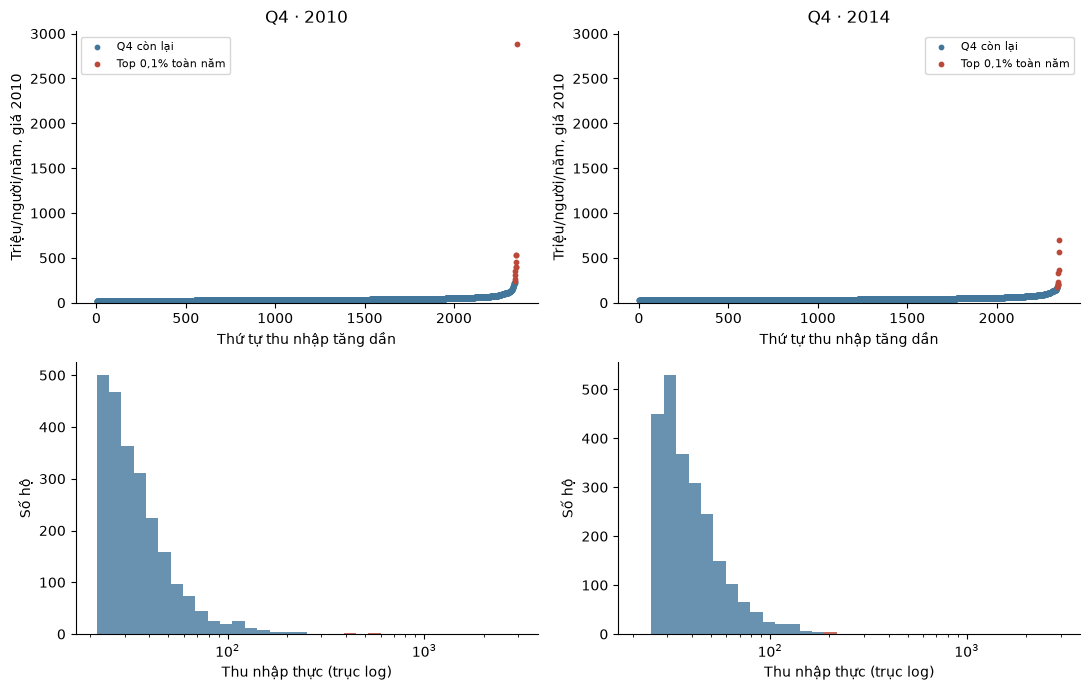

,year,mean,median,top_ss_pct,zero_income_not_on_log
0,2010,40.293,30.928,89.303,0
1,2014,43.390,35.876,53.630,0


In [23]:
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
q4_data = income_data.loc[income_data["quart"].eq(4)]
positive_income = q4_data.loc[q4_data["income_pc_real"].gt(0), "income_pc_real"]
bins = np.geomspace(positive_income.min() * 0.98, positive_income.max() * 1.02, 35)
q4_description = []

for column, year in enumerate(ANALYSIS_YEARS):
    frame = q4_data.loc[q4_data["year"].eq(year)].sort_values("income_pc_real")
    values = frame["income_pc_real"].to_numpy()
    top_mask = frame["record_id"].isin(removed_income["record_id"]).to_numpy()
    ranks = np.arange(1, len(frame) + 1)
    for mask, color, label in [(~top_mask, "#42779b", "Q4 còn lại"),
                               (top_mask, "#bb4939", "Top 0,1% toàn năm")]:
        axes[0, column].scatter(ranks[mask], values[mask], s=10, color=color, label=label)
        axes[1, column].hist(values[mask & (values > 0)], bins=bins, color=color, alpha=0.8)
    axes[0, column].set(title=f"Q4 · {year}", xlabel="Thứ tự thu nhập tăng dần",
                        ylabel="Triệu/người/năm, giá 2010", ylim=(0, q4_data["income_pc_real"].max() * 1.05))
    axes[0, column].legend(fontsize=8)
    axes[1, column].set(xscale="log", xlabel="Thu nhập thực (trục log)", ylabel="Số hộ")
    squared_deviations = (values - values.mean())**2
    q4_description.append({"year": year, "mean": values.mean(), "median": np.median(values),
                           "top_ss_pct": 100 * squared_deviations[top_mask].sum() / squared_deviations.sum(),
                           "zero_income_not_on_log": int((values == 0).sum())})
figure.tight_layout()
plt.show()
display(pd.DataFrame(q4_description).round(3))

### A.2. Kiểm tra phân phối theo nhóm

Tính n, mean, median, skewness, Jarque–Bera và phần SS do quan sát lớn nhất trong từng mẫu sẽ kiểm định.

JB kiểm tra phân phối thu nhập, không phải phân phối của mean. Mẫu lớn vẫn có thể nhạy với đuôi trên.

In [24]:
GROUP_FILTERS = {
    "Toàn mẫu": (None, None),
    "Q1": ("quart", 1), "Q2": ("quart", 2), "Q3": ("quart", 3), "Q4": ("quart", 4),
    "Thành thị": ("area", 1), "Nông thôn": ("area", 2),
}


def income_group(frame, group):
    column, value = GROUP_FILTERS[group]
    selected = frame if column is None else frame.loc[frame[column].eq(value).fillna(False)]
    return selected["income_pc_real"].dropna().to_numpy()


diagnostic_rows = []
for (version, year), frame in income_samples.items():
    for group in GROUP_FILTERS:
        values = income_group(frame, group)
        jb = jarque_bera_test(values)
        squared_deviations = (values - values.mean())**2
        diagnostic_rows.append({
            "sample": version, "year": year, "group": group, "n": len(values),
            "mean": values.mean(), "median": np.median(values), "skewness": jb["skewness"],
            "jb_p": jb["p_value"], "reject_normality": jb["reject_h0"],
            "largest_ss_pct": 100 * squared_deviations.max() / squared_deviations.sum(),
        })
income_diagnostics = pd.DataFrame(diagnostic_rows)
for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
    display(Markdown(f"**{version}**"))
    display(income_diagnostics.loc[income_diagnostics["sample"].eq(version)].drop(columns="sample").round(3))

**Toàn mẫu**

,year,group,n,mean,median,skewness,jb_p,reject_normality,largest_ss_pct
0,2010,Toàn mẫu,9399,18.257,13.168,56.001,0.000,True,67.987
1,2010,Q1,2350,5.257,5.383,-0.334,0.000,True,0.366
2,2010,Q2,2349,10.382,10.336,0.053,0.000,True,0.143
3,2010,Q3,2350,17.093,16.781,0.252,0.000,True,0.155
4,2010,Q4,2350,40.293,30.928,34.200,0.000,True,78.007
5,2010,Thành thị,2649,27.089,21.115,5.704,0.000,True,7.578
6,2010,Nông thôn,6750,14.791,11.020,62.570,0.000,True,82.430
14,2014,Toàn mẫu,9398,20.861,16.431,9.126,0.000,True,11.977
15,2014,Q1,2352,6.292,6.390,-0.215,0.000,True,0.309
16,2014,Q2,2350,13.024,12.989,0.043,0.000,True,0.130


**Bỏ top 0,1%**

,year,group,n,mean,median,skewness,jb_p,reject_normality,largest_ss_pct
7,2010,Toàn mẫu,9389,17.598,13.152,4.045,0.000,True,1.873
8,2010,Q1,2350,5.257,5.383,-0.334,0.000,True,0.366
9,2010,Q2,2349,10.382,10.336,0.053,0.000,True,0.143
10,2010,Q3,2350,17.093,16.781,0.252,0.000,True,0.155
11,2010,Q4,2340,37.744,30.826,3.827,0.000,True,3.600
12,2010,Thành thị,2643,26.406,21.093,3.332,0.000,True,3.546
13,2010,Nông thôn,6746,14.147,11.012,4.497,0.000,True,4.300
21,2014,Toàn mẫu,9388,20.543,16.424,2.760,0.000,True,0.909
22,2014,Q1,2352,6.292,6.390,-0.215,0.000,True,0.309
23,2014,Q2,2350,13.024,12.989,0.043,0.000,True,0.130


### A.3. Kiểm định mức tăng

Đặt `x` là năm 2014, `y` là năm 2010. Dùng Welch t phía phải và CI 95% hai phía cho chênh lệch mean. Các p và CI áp dụng riêng từng so sánh.

In [25]:
result_rows = []
for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
    for group in GROUP_FILTERS:
        earlier = income_group(income_samples[(version, 2010)], group)
        later = income_group(income_samples[(version, 2014)], group)
        test = independent_t_test(later, earlier, alternative="greater")
        result_rows.append({
            "sample": version, "group": group, "n_2010": len(earlier), "n_2014": len(later),
            "mean_2010": earlier.mean(), "mean_2014": later.mean(),
            "growth_pct": 100 * test["estimate"] / earlier.mean(), **test,
        })
income_results = pd.DataFrame(result_rows)

In [26]:
def show_income_results(groups):
    """Hiển thị kết quả của các nhóm được chọn."""
    selected = income_results.loc[income_results["group"].isin(groups)]
    for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
        table = selected.loc[selected["sample"].eq(version)].copy()
        table["CI 95%"] = [f"[{low:.3f}; {high:.3f}]" for low, high in zip(table["ci_low"], table["ci_high"])]
        table["Kết luận 5%"] = np.where(table["reject_h0"], "Bác bỏ H₀", "Không bác bỏ H₀")
        table = table[["group", "mean_2010", "mean_2014", "estimate", "growth_pct", "CI 95%", "p_value", "Kết luận 5%"]]
        table = table.rename(columns={"group": "Nhóm", "mean_2010": "Mean 2010", "mean_2014": "Mean 2014",
                                      "estimate": "Mức tăng", "growth_pct": "Tăng (%)", "p_value": "p phía phải"})
        display(Markdown(f"**{version}** · triệu đồng/người/năm, giá 2010"))
        display(table.style.hide(axis="index").format({
            "Mean 2010": "{:.3f}", "Mean 2014": "{:.3f}", "Mức tăng": "{:.3f}",
            "Tăng (%)": "{:.2f}", "p phía phải": "{:.3e}",
        }))

### Câu 1. Thu nhập thực bình quân toàn mẫu có tăng không?

H₀: μ2014 − μ2010 = 0; H₁: μ2014 − μ2010 > 0. Mean của toàn mẫu hợp lệ từng năm; Welch t phía phải, CI 95% hai phía.

In [27]:
show_income_results(["Toàn mẫu"])

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Toàn mẫu,18.257,20.861,2.604,14.26,[1.771; 3.436],4.445e-10,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Toàn mẫu,17.598,20.543,2.944,16.73,[2.468; 3.421],5.617e-34,Bác bỏ H₀


### Câu 2. Mức tăng trong Q1–Q4

Với từng q: H₀: μq,2014 − μq,2010 = 0; H₁: μq,2014 − μq,2010 > 0. Welch t phía phải cho từng Q; CI 95% của chênh lệch mean. Nhãn Q là nhóm của từng năm, không theo dõi cùng hộ.

In [28]:
show_income_results(["Q1", "Q2", "Q3", "Q4"])

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Q1,5.257,6.292,1.035,19.69,[0.931; 1.139],3.043e-81,Bác bỏ H₀
Q2,10.382,13.024,2.642,25.45,[2.542; 2.742],0.000e+00,Bác bỏ H₀
Q3,17.093,20.758,3.665,21.44,[3.514; 3.816],0.000e+00,Bác bỏ H₀
Q4,40.293,43.390,3.097,7.69,[0.166; 6.029],1.919e-02,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Q1,5.257,6.292,1.035,19.69,[0.931; 1.139],3.043e-81,Bác bỏ H₀
Q2,10.382,13.024,2.642,25.45,[2.542; 2.742],0.000e+00,Bác bỏ H₀
Q3,17.093,20.758,3.665,21.44,[3.514; 3.816],0.000e+00,Bác bỏ H₀
Q4,37.744,42.210,4.467,11.83,[3.281; 5.652],8.931e-14,Bác bỏ H₀


### Câu 3. Mức tăng tại thành thị và nông thôn

Với mỗi khu vực a: H₀: μa,2014 − μa,2010 = 0; H₁: μa,2014 − μa,2010 > 0. So sánh cùng khu vực giữa hai mẫu năm; Welch t phía phải, CI 95%. Chưa kiểm định chênh lệch mức tăng giữa hai khu vực.

In [29]:
show_income_results(["Thành thị", "Nông thôn"])

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Thành thị,27.089,29.532,2.444,9.02,[1.110; 3.778],1.662e-04,Bác bỏ H₀
Nông thôn,14.791,17.216,2.425,16.39,[1.418; 3.432],1.193e-06,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Thành thị,26.406,28.965,2.559,9.69,[1.458; 3.661],2.681e-06,Bác bỏ H₀
Nông thôn,14.147,17.008,2.861,20.22,[2.412; 3.310],6.962e-36,Bác bỏ H₀


### A.4. Mức tăng và CI 95%

Các khoảng là CI riêng của chênh lệch mean 2014 − 2010. Đường đứt nét là mốc 0. CI hai phía và kiểm định một phía mức 5% có ngưỡng kết luận khác nhau.

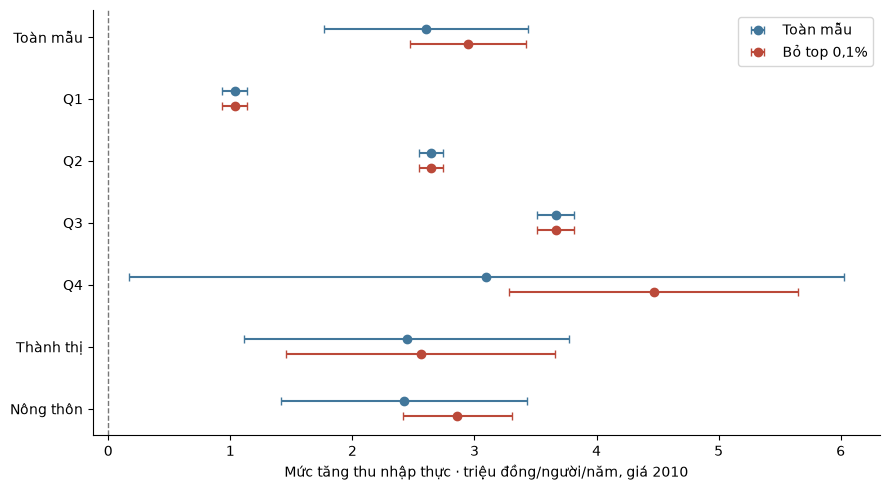

In [30]:
figure, axis = plt.subplots(figsize=(9, 5))
groups = list(GROUP_FILTERS)
for version, offset, color in [("Toàn mẫu", -0.12, "#42779b"), ("Bỏ top 0,1%", 0.12, "#bb4939")]:
    rows = income_results.loc[income_results["sample"].eq(version)].set_index("group").loc[groups]
    axis.errorbar(rows["estimate"], np.arange(len(groups)) + offset,
                  xerr=[rows["estimate"] - rows["ci_low"], rows["ci_high"] - rows["estimate"]],
                  fmt="o", capsize=3, color=color, label=version)
axis.axvline(0, color="#777777", linestyle="--", linewidth=1)
axis.set(yticks=np.arange(len(groups)), yticklabels=groups,
         xlabel="Mức tăng thu nhập thực · triệu đồng/người/năm, giá 2010")
axis.invert_yaxis()
axis.legend()
figure.tight_layout()
plt.show()

### Nhận xét

- Thu nhập thực bình quân toàn mẫu tăng **2,604 triệu/người/năm (14,26%)**. Bản bỏ top 0,1% tăng **2,944 triệu (16,73%)**.
- Q1 tăng **1,035 triệu/người/năm**, khoảng **86 nghìn/người/tháng** theo giá 2010. Các Q còn lại và cả hai khu vực cũng có bằng chứng mean tăng theo từng kiểm định xấp xỉ.
- Q4 nhạy với đuôi trên: bỏ top 0,1% làm mức tăng ước lượng lớn hơn và CI hẹp hơn. Các hộ này chưa được xác định là ghi sai.

Đây là thay đổi giữa hai mẫu, không phải thay đổi của cùng hộ. Mean dùng trọng số hộ bằng nhau; p/CI chưa xét thiết kế khảo sát, giá vùng, bất định chia Quart và đầy đủ bất định chọn ngưỡng lọc. Kết quả thu nhập chưa đủ để kết luận mọi mặt của mức sống đều cải thiện.

### A.5. Kiểm tra lại kết quả

Đối chiếu 14 phép Welch và CI với SciPy; kiểm tra số dòng và nhóm bị loại. Kết quả giữ trong notebook, không xuất thêm bảng rời.

Dữ liệu sạch đọc bằng `pd.read_csv("processed/vhlss_processed.csv")`. Các ô trống trong `owns_*` vẫn là chưa rõ sở hữu.

In [31]:
for row in income_results.itertuples():
    earlier = income_group(income_samples[(row.sample, 2010)], row.group)
    later = income_group(income_samples[(row.sample, 2014)], row.group)
    reference = stats.ttest_ind(later, earlier, equal_var=False, alternative="greater")
    interval = stats.ttest_ind(later, earlier, equal_var=False).confidence_interval(CONFIDENCE_LEVEL)
    np.testing.assert_allclose([row.statistic, row.df], [reference.statistic, reference.df])
    np.testing.assert_allclose(row.p_value, reference.pvalue, rtol=1e-10, atol=0)
    np.testing.assert_allclose([row.ci_low, row.ci_high], [interval.low, interval.high])

for year in ANALYSIS_YEARS:
    original = income_samples[("Toàn mẫu", year)]
    retained = income_samples[("Bỏ top 0,1%", year)]
    removed = removed_income.loc[removed_income["year"].eq(year)]
    assert len(removed) == int(np.ceil(TOP_FRACTION * len(original)))
    assert set(retained["record_id"]).isdisjoint(removed["record_id"])
    assert len(retained) + len(removed) == len(original)
    for group in ["Q1", "Q2", "Q3"]:
        np.testing.assert_allclose(np.sort(income_group(original, group)), np.sort(income_group(retained, group)))

assert len(income_results) == 14
saved = pd.read_csv(processed_path)
assert saved.shape == data.shape
print("14 phép kiểm định và CI khớp SciPy.")

14 phép kiểm định và CI khớp SciPy.


## B. Chi Tiêu

Chưa triển khai phân tích trong bản này.

## C. Thu - Chi

Chưa triển khai phân tích trong bản này.

## D. Tài Sản

Theo phần tài sản trong [notebook được cung cấp](https://colab.research.google.com/drive/1mtAVFZxFl1JkVguy4Sq_5tLt_FAegXmE): tổng tài sản bền, thành thị–nông thôn, giá trị và tỷ lệ sở hữu thiết bị công nghệ.

Dùng dữ liệu processed của **2010/2014**, không áp dụng bộ lọc top thu nhập. Giá trị tài sản tính theo **triệu đồng/hộ, giá 2010**. Đây là giá trị tại khảo sát, không phải chi mua tài sản trong năm; CPI chung chỉ là cách quy giá xấp xỉ.

### D.1. Tổng giá trị 9 tài sản bền

Gồm ô tô, xe máy, xe đạp, giường, bàn ghế, điện thoại, tivi, thiết bị giải trí và gia dụng; **không gồm nhà**. Chỉ tính tổng khi đủ cả 9 giá trị. Hộ thiếu một khoản vẫn được giữ trong `data`, nhưng không có tổng đầy đủ.

In [32]:
DURABLE_ASSETS = [column for column in ASSET_COLUMNS if column != "house"]
TECH_ASSETS = ["tele", "tv", "emachine", "hmachine"]
TECH_NAMES = {
    "tele": "Điện thoại", "tv": "Tivi",
    "emachine": "Thiết bị giải trí", "hmachine": "Thiết bị gia dụng",
}
TECH_OWNERSHIP = [f"owns_{column}" for column in TECH_ASSETS]

asset_data = data.loc[data["year"].isin(ANALYSIS_YEARS)].copy()
real_durable_columns = [f"{column}_real_2010" for column in DURABLE_ASSETS]
asset_data["durable_total_real"] = asset_data[real_durable_columns].sum(axis=1, min_count=9) / 1000
asset_data["device_count"] = asset_data[TECH_OWNERSHIP].sum(axis=1, min_count=4)

asset_sample_audit = asset_data.groupby("year").agg(
    households=("record_id", "size"), complete_9=("durable_total_real", "count"),
    complete_4_tech=("device_count", "count"),
)
asset_sample_audit["missing_9"] = asset_sample_audit["households"] - asset_sample_audit["complete_9"]
display(asset_sample_audit)

,households,complete_9,complete_4_tech,missing_9
year,,,,
2010,9399,9212,9215,187
2014,9398,9349,9352,49


In [33]:
asset_values = {}
asset_description_rows = []
asset_shape_rows = []
for year in ANALYSIS_YEARS:
    values = asset_data.loc[asset_data["year"].eq(year), "durable_total_real"].dropna().to_numpy()
    asset_values[year] = values
    asset_description_rows.append({"year": year, **describe_with_ci(values)})

    log_values = np.log(values[values > 0])
    skew_low, skew_high = bootstrap_skew_ci(values)
    log_low, log_high = bootstrap_skew_ci(log_values)
    asset_shape_rows.append({
        "year": year, "skewness": stats.skew(values, bias=False),
        "skew_ci_low": skew_low, "skew_ci_high": skew_high,
        "excess_kurtosis": stats.kurtosis(values), "n_positive": len(log_values),
        "log_skewness": stats.skew(log_values, bias=False),
        "log_skew_ci_low": log_low, "log_skew_ci_high": log_high,
        "geometric_mean_positive": np.exp(log_values.mean()),
    })

asset_description = pd.DataFrame(asset_description_rows).set_index("year")
asset_shape = pd.DataFrame(asset_shape_rows).set_index("year")
display(asset_description.T.round(3))
display(asset_shape.T.round(3))

year,2010,2014
n,"9,212.000","9,349.000"
mean,25.786,23.330
ci_low,24.354,22.298
ci_high,27.218,24.363
median,12.570,12.680
p25,5.428,5.568
p75,26.258,25.332
p99,194.507,244.751
max,"2,521.700",981.836
std,70.107,50.921


year,2010,2014
skewness,14.786,9.213
skew_ci_low,10.995,8.342
skew_ci_high,18.444,9.996
excess_kurtosis,329.632,110.423
n_positive,"9,212.000","9,347.000"
log_skewness,-0.541,-0.573
log_skew_ci_low,-0.606,-0.650
log_skew_ci_high,-0.466,-0.491
geometric_mean_positive,11.086,11.010


CI mean, median và các phân vị có đơn vị triệu đồng/hộ. Skewness/kurtosis không có đơn vị. Log và trung bình nhân chỉ dùng các hộ có tổng tài sản > 0; các hộ có tổng bằng 0 vẫn được giữ khi tính mean và kiểm định trên thang tiền.

In [34]:
asset_diagnostic_rows = []
for year, frame in asset_data.groupby("year"):
    samples = {"Toàn mẫu": frame["durable_total_real"]}
    for area, name in [(1, "Thành thị"), (2, "Nông thôn")]:
        samples[name] = frame.loc[frame["area"].eq(area), "durable_total_real"]
    for group, sample in samples.items():
        jb = jarque_bera_test(sample.dropna())
        asset_diagnostic_rows.append({
            "year": year, "group": group, "n": jb["n"], "skewness": jb["skewness"],
            "jb_p": jb["p_value"], "reject_normality": jb["reject_h0"],
        })
asset_diagnostics = pd.DataFrame(asset_diagnostic_rows)
display(asset_diagnostics.round(3))

,year,group,n,skewness,jb_p,reject_normality
0,2010,Toàn mẫu,9212,14.783,0.000,True
1,2010,Thành thị,2619,7.484,0.000,True
2,2010,Nông thôn,6593,28.644,0.000,True
3,2014,Toàn mẫu,9349,9.212,0.000,True
4,2014,Thành thị,2777,6.231,0.000,True
5,2014,Nông thôn,6572,12.604,0.000,True


**So sánh hai năm:** Δ = μ2014 − μ2010; H₀: Δ = 0; H₁: Δ ≠ 0. Dùng Welch t hai phía, Chap 7 §7.2.4; CI 95% hai phía của chênh lệch mean. Hai mẫu độc lập; do phân phối lệch và nhạy với đuôi trên, p/CI được đọc như xấp xỉ cho mean, cùng bảng phân phối.

In [35]:
asset_change = independent_t_test(asset_values[2014], asset_values[2010])
display(pd.DataFrame([asset_change])[
    ["estimate", "se", "statistic", "df", "p_value", "ci_low", "ci_high", "reject_h0"]
].style.hide(axis="index").format({"p_value": "{:.3e}"}))

estimate,se,statistic,df,p_value,ci_low,ci_high,reject_h0
-2.455456,0.900497,-2.726778,16802.394965,6.402e-03,-4.220526,-0.690387,True


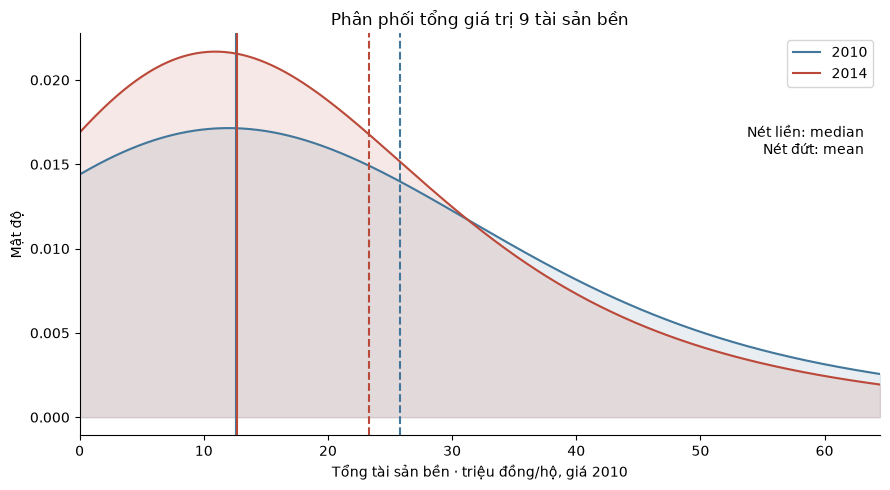

In [36]:
figure, axis = plt.subplots(figsize=(9, 5))
x_limit = 2.5 * asset_values[2010].mean()
grid = np.linspace(0, x_limit, 500)
for year, color in [(2010, "#42779b"), (2014, "#bb4939")]:
    values = asset_values[year]
    density = stats.gaussian_kde(values, bw_method=0.25)(grid)
    axis.plot(grid, density, color=color, label=str(year))
    axis.fill_between(grid, density, color=color, alpha=0.12)
    axis.axvline(np.median(values), color=color, linestyle="-")
    axis.axvline(values.mean(), color=color, linestyle="--")
axis.set(xlim=(0, x_limit), xlabel="Tổng tài sản bền · triệu đồng/hộ, giá 2010", ylabel="Mật độ",
         title="Phân phối tổng giá trị 9 tài sản bền")
axis.text(0.98, 0.7, "Nét liền: median\nNét đứt: mean", transform=axis.transAxes, ha="right")
axis.legend()
figure.tight_layout()
plt.show()

Biểu đồ giới hạn vùng hiển thị để thấy mean và median. KDE và kiểm định vẫn dùng toàn bộ mẫu đủ 9 khoản, không cắt các giá trị lớn trước khi ước lượng mật độ.

### D.2. Thành thị và nông thôn

Mỗi năm so sánh Δ = μthành thị − μnông thôn; H₀: Δ = 0; H₁: Δ ≠ 0. Dùng Welch t hai phía, CI 95%. Tỷ số hai mean chỉ mô tả; các kiểm định này chưa trả lời khoảng cách thay đổi ra sao giữa hai năm.

In [37]:
asset_area_rows = []
asset_area_test_rows = []
for year, frame in asset_data.groupby("year"):
    area_samples = {}
    for area, name in [(1, "Thành thị"), (2, "Nông thôn")]:
        values = frame.loc[frame["area"].eq(area), "durable_total_real"].dropna().to_numpy()
        area_samples[name] = values
        asset_area_rows.append({"year": year, "area": name, **describe_with_ci(values)})
    urban, rural = area_samples["Thành thị"], area_samples["Nông thôn"]
    asset_area_test_rows.append({
        "year": year, "urban_rural_ratio": urban.mean() / rural.mean(),
        **independent_t_test(urban, rural),
    })
asset_area_description = pd.DataFrame(asset_area_rows)
asset_area_tests = pd.DataFrame(asset_area_test_rows)
display(asset_area_description[["year", "area", "n", "mean", "ci_low", "ci_high", "median"]].round(3))
display(asset_area_tests[["year", "estimate", "ci_low", "ci_high", "urban_rural_ratio", "statistic", "df", "p_value"]]
        .style.hide(axis="index").format({"p_value": "{:.3e}"}))

,year,area,n,mean,ci_low,ci_high,median
0,2010,Thành thị,2619,44.788,40.942,48.635,22.400
1,2010,Nông thôn,6593,18.237,16.991,19.484,10.250
2,2014,Thành thị,2777,37.418,34.543,40.293,19.834
3,2014,Nông thôn,6572,17.378,16.595,18.160,10.578


year,estimate,ci_low,ci_high,urban_rural_ratio,statistic,df,p_value
2010,26.551078,22.508150,30.594006,2.455867,12.876546,3183.146383,5.043e-37
2014,20.040596,17.060886,23.020306,2.153243,13.187098,3195.105259,1.049e-38


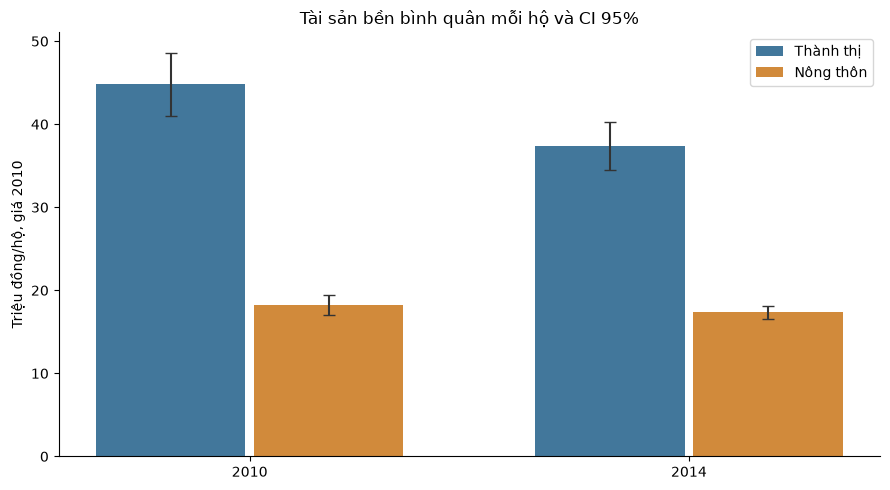

In [38]:
figure, axis = plt.subplots(figsize=(9, 5))
positions = np.arange(len(ANALYSIS_YEARS))
for name, offset, color in [("Thành thị", -0.18, "#42779b"), ("Nông thôn", 0.18, "#d18a3b")]:
    rows = asset_area_description.loc[asset_area_description["area"].eq(name)].set_index("year").loc[ANALYSIS_YEARS]
    errors = [rows["mean"] - rows["ci_low"], rows["ci_high"] - rows["mean"]]
    axis.bar(positions + offset, rows["mean"], width=0.34, color=color, label=name)
    axis.errorbar(positions + offset, rows["mean"], yerr=errors, fmt="none", color="#333333", capsize=4)
axis.set(xticks=positions, xticklabels=ANALYSIS_YEARS, ylabel="Triệu đồng/hộ, giá 2010",
         title="Tài sản bền bình quân mỗi hộ và CI 95%")
axis.legend()
figure.tight_layout()
plt.show()

### D.3. Giá trị thiết bị công nghệ theo Q

Giá trị bình quân từng thiết bị tính trên các hộ biết giá trị của thiết bị đó, gồm cả số 0. Đơn vị triệu đồng/hộ, giá 2010; không gọi đây là chi mua thiết bị trong năm.

In [39]:
tech_value_columns = [f"{column}_real_2010" for column in TECH_ASSETS]
tech_value_rows = []
for (year, quart), frame in asset_data.groupby(["year", "quart"]):
    scopes = [("Toàn mẫu", frame)]
    scopes += [(name, frame.loc[frame["area"].eq(area)])
               for area, name in [(1, "Thành thị"), (2, "Nông thôn")]]
    for area, selected in scopes:
        for asset, value_column in zip(TECH_ASSETS, tech_value_columns):
            values = selected[value_column] / 1000
            tech_value_rows.append({
                "year": year, "quart": f"Q{quart}", "area": area, "asset": TECH_NAMES[asset],
                "n": values.count(), "missing": values.isna().sum(), "mean": values.mean(),
            })
tech_value_by_group = pd.DataFrame(tech_value_rows)
display(tech_value_by_group.pivot(index=["year", "area", "quart"], columns="asset", values="mean").round(3))

asset                 Thiết bị gia dụng  Thiết bị giải trí  Tivi  Điện thoại
year area      quart                                                        
2010 Nông thôn Q1                 1.542              0.225 0.738       0.278
               Q2                 3.294              0.342 0.879       0.537
               Q3                 5.808              0.502 1.164       0.978
               Q4                10.629              0.774 1.560       1.717
     Thành thị Q1                 1.953              0.254 0.642       0.351
               Q2                 3.713              0.392 1.041       0.611
               Q3                 7.243              0.544 1.386       1.402
               Q4                16.056              0.951 3.139       2.892
     Toàn mẫu  Q1                 1.576              0.228 0.730       0.284
               Q2                 3.371              0.352 0.909       0.551
               Q3                 6.276              0.515 1.236       1.116
               Q4                13.519              0.868 2.401       2.343
2014 Nông thôn Q1                 0.856              0.140 0.513       0.303
               Q2                 2.101              0.276 0.796       0.566
               Q3                 3.304              0.452 1.089       0.861
               Q4                 4.910              0.752 1.627       1.411
     Thành thị Q1                 1.247              0.167 0.536       0.401
               Q2                 2.462              0.258 0.902       0.729
               Q3                 4.177              0.445 1.469       1.359
               Q4                 7.193              0.922 2.517       2.485
     Toàn mẫu  Q1                 0.891              0.142 0.515       0.312
               Q2                 2.173              0.272 0.818       0.599
               Q3                 3.626              0.449 1.229       1.045
               Q4                 6.114              0.841 2.096       1.977

In [40]:
tech_2014 = asset_data.loc[asset_data["year"].eq(2014)].copy()
tech_2014["q_group"] = tech_2014["quart"].map({1: "Q1–Q2", 2: "Q1–Q2", 3: "Q3–Q4", 4: "Q3–Q4"})
tech_long = tech_2014.melt(
    id_vars=["record_id", "q_group"], value_vars=tech_value_columns,
    var_name="asset", value_name="value_real",
)
tech_long["asset"] = tech_long["asset"].map({f"{asset}_real_2010": TECH_NAMES[asset] for asset in TECH_ASSETS})
tech_long["value_real"] = tech_long["value_real"] / 1000
tech_q_summary = tech_long.groupby(["q_group", "asset"])["value_real"].agg(n="count", mean="mean", median="median")
display(tech_q_summary.round(3))

n  mean  median
q_group asset                                
Q1–Q2   Thiết bị gia dụng  4660 1.537   0.766
        Thiết bị giải trí  4661 0.208   0.000
        Tivi               4661 0.667   0.418
        Điện thoại         4660 0.456   0.278
Q3–Q4   Thiết bị gia dụng  4693 4.871   3.480
        Thiết bị giải trí  4693 0.645   0.209
        Tivi               4693 1.663   0.766
        Điện thoại         4693 1.511   0.766

**Về ANOVA trong bản nguồn:** mỗi hộ cung cấp bốn giá trị thiết bị, nên các dòng sau `melt` không độc lập. Dữ liệu còn có ô thiếu và phương sai khác nhau. Vì vậy giữ bảng mô tả Q1–Q2/Q3–Q4, không dùng F/p của ANOVA hai nhân tố độc lập để kết luận. Hàm ANOVA cân bằng ở phần 4 không phù hợp với cấu trúc này.

### D.4. Tỷ lệ sở hữu thiết bị công nghệ

Với mỗi thiết bị: H₀: p2014 − p2010 = 0; H₁: p2014 − p2010 ≠ 0. Dùng Z hai tỷ lệ, Chap 7 §7.4; mẫu số là số hộ **biết trạng thái của đúng thiết bị đó**. Thiếu/âm không đổi thành không sở hữu.

CI 95% của chênh lệch tỷ lệ trình bày theo **điểm phần trăm**. Theo bản nguồn, bổ sung p Bonferroni cho 4 phép toàn mẫu và 16 phép theo Quart; CI vẫn là 95% riêng lẻ, chưa phải CI đồng thời.

In [41]:
tech_ownership_rows = []
for group in ["Toàn mẫu", "Q1", "Q2", "Q3", "Q4"]:
    frame = asset_data if group == "Toàn mẫu" else asset_data.loc[asset_data["quart"].eq(int(group[1:]))]
    for asset in TECH_ASSETS:
        earlier = frame.loc[frame["year"].eq(2010), f"owns_{asset}"].dropna().to_numpy(dtype=float)
        later = frame.loc[frame["year"].eq(2014), f"owns_{asset}"].dropna().to_numpy(dtype=float)
        test = two_proportion_test(later.sum(), len(later), earlier.sum(), len(earlier))
        family_size = 4 if group == "Toàn mẫu" else 16
        tech_ownership_rows.append({
            "group": group, "asset": TECH_NAMES[asset], "asset_code": asset,
            "n_2010": len(earlier), "n_2014": len(later),
            "rate_2010_pct": 100 * earlier.mean(), "rate_2014_pct": 100 * later.mean(),
            "change_pp": 100 * test["estimate"], "ci_low_pp": 100 * test["ci_low"],
            "ci_high_pp": 100 * test["ci_high"], "z": test["statistic"],
            "p_value": test["p_value"], "p_bonferroni": min(1, family_size * test["p_value"]),
            "reject_h0": test["reject_h0"],
        })
tech_ownership_results = pd.DataFrame(tech_ownership_rows)
tech_ownership_results["reject_bonferroni"] = tech_ownership_results["p_bonferroni"].lt(ALPHA)
ownership_columns = ["asset", "n_2010", "n_2014", "rate_2010_pct", "rate_2014_pct",
                     "change_pp", "ci_low_pp", "ci_high_pp", "p_value", "p_bonferroni"]
display(tech_ownership_results.loc[tech_ownership_results["group"].eq("Toàn mẫu"), ownership_columns]
        .style.hide(axis="index").format({"p_value": "{:.3e}", "p_bonferroni": "{:.3e}"}))

asset,n_2010,n_2014,rate_2010_pct,rate_2014_pct,change_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni
Điện thoại,9217,9353,76.847130,89.842831,12.995701,11.939127,14.052275,3.947e-125,1.579e-124
Tivi,9218,9354,82.696897,92.302758,9.605861,8.663478,10.548244,2.224e-87,8.898e-87
Thiết bị giải trí,9221,9354,58.073962,57.451358,-0.622604,-2.043247,0.798039,3.904e-01,1.000e+00
Thiết bị gia dụng,9218,9353,94.781948,94.803806,0.021858,-0.617232,0.660948,9.466e-01,1.000e+00


In [42]:
for asset in TECH_NAMES.values():
    display(Markdown(f"**{asset} · theo Quart**"))
    rows = tech_ownership_results.loc[tech_ownership_results["asset"].eq(asset)
                                     & tech_ownership_results["group"].ne("Toàn mẫu")]
    display(rows[["group", *ownership_columns[1:]]].style.hide(axis="index")
            .format({"p_value": "{:.3e}", "p_bonferroni": "{:.3e}"}))

**Điện thoại · theo Quart**

group,n_2010,n_2014,rate_2010_pct,rate_2014_pct,change_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni
Q1,2212,2312,54.430380,74.956747,20.526368,17.801210,23.251526,2.115e-47,3.384e-46
Q2,2325,2348,74.623656,91.439523,16.815867,14.715997,18.915738,5.035e-53,8.056e-52
Q3,2337,2345,85.579803,95.778252,10.198448,8.558049,11.838848,3.284e-33,5.254e-32
Q4,2343,2348,91.506615,96.976150,5.469534,4.145142,6.793927,8.822e-16,1.412e-14


**Tivi · theo Quart**

group,n_2010,n_2014,rate_2010_pct,rate_2014_pct,change_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni
Q1,2212,2313,73.236890,80.112408,6.875518,4.415847,9.335190,4.422e-08,7.075e-07
Q2,2326,2348,83.533964,94.420784,10.886820,9.116650,12.656989,1.254e-32,2.006e-31
Q3,2337,2345,86.050492,97.825160,11.774668,10.250980,13.298356,1.360e-49,2.176e-48
Q4,2343,2348,87.451985,96.678024,9.226039,7.701377,10.750701,1.387e-31,2.219e-30


**Thiết bị giải trí · theo Quart**

group,n_2010,n_2014,rate_2010_pct,rate_2014_pct,change_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni
Q1,2213,2313,43.651152,41.115435,-2.535718,-5.415061,0.343625,8.438e-02,1.000e+00
Q2,2327,2348,57.455952,56.260647,-1.195305,-4.034546,1.643937,4.093e-01,1.000e+00
Q3,2338,2345,63.857998,64.477612,0.619614,-2.127040,3.366268,6.584e-01,1.000e+00
Q4,2343,2348,66.538626,67.717206,1.178580,-1.509726,3.866887,3.902e-01,1.000e+00


**Thiết bị gia dụng · theo Quart**

group,n_2010,n_2014,rate_2010_pct,rate_2014_pct,change_pp,ci_low_pp,ci_high_pp,p_value,p_bonferroni
Q1,2212,2312,85.895118,82.482699,-3.412419,-5.534851,-1.289986,1.680e-03,2.688e-02
Q2,2325,2348,95.956989,97.657581,1.700592,0.692995,2.708188,9.387e-04,1.502e-02
Q3,2338,2345,97.818648,99.275053,1.456405,0.771945,2.140865,3.103e-05,4.964e-04
Q4,2343,2348,98.975672,99.616695,0.641023,0.162804,1.119242,8.626e-03,1.380e-01


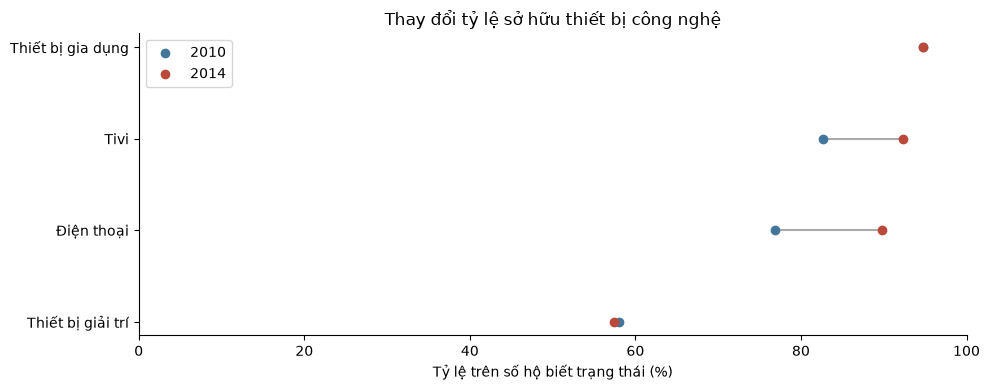

In [43]:
figure, axis = plt.subplots(figsize=(10, 4))
rows = tech_ownership_results.loc[tech_ownership_results["group"].eq("Toàn mẫu")].sort_values("rate_2014_pct")
for position, row in enumerate(rows.itertuples()):
    axis.plot([row.rate_2010_pct, row.rate_2014_pct], [position, position], color="#aaaaaa")
positions = np.arange(len(rows))
axis.scatter(rows["rate_2010_pct"], positions, color="#42779b", label="2010", zorder=3)
axis.scatter(rows["rate_2014_pct"], positions, color="#bb4939", label="2014", zorder=3)
axis.set(yticks=positions, yticklabels=rows["asset"], xlim=(0, 100),
         xlabel="Tỷ lệ trên số hộ biết trạng thái (%)", title="Thay đổi tỷ lệ sở hữu thiết bị công nghệ")
axis.legend()
figure.tight_layout()
plt.show()

**Sở hữu có liên hệ với Quart không?** Với mỗi năm và thiết bị, H₀: Quart và trạng thái sở hữu độc lập; H₁: không độc lập. Dùng χ² bảng 4×2, df = 3, Chap 9 §9.2. Kiểm tra mọi tần số kỳ vọng ≥ 5. Đây là liên hệ trong mẫu, không phải tác động nhân quả của thu nhập.

In [44]:
tech_quart_rows = []
for year, frame in asset_data.groupby("year"):
    for asset in TECH_ASSETS:
        counts = pd.crosstab(frame["quart"], frame[f"owns_{asset}"])
        test = chi_square_independence(counts)
        tech_quart_rows.append({
            "year": year, "asset": TECH_NAMES[asset], "n": counts.to_numpy().sum(),
            "chi2": test["statistic"], "df": test["df"],
            "min_expected": test["expected"].min(), "p_value": test["p_value"],
            "p_bonferroni_8": min(1, 8 * test["p_value"]),
        })
tech_quart_tests = pd.DataFrame(tech_quart_rows)
display(tech_quart_tests.style.hide(axis="index")
        .format({"p_value": "{:.3e}", "p_bonferroni_8": "{:.3e}"}))

year,asset,n,chi2,df,min_expected,p_value,p_bonferroni_8
2010,Điện thoại,9217,1014.358457,3,512.141478,1.381e-219,1.105e-218
2010,Tivi,9218,194.872835,3,382.744630,5.407e-42,4.325e-41
2010,Thiết bị giải trí,9221,290.505703,3,927.823230,1.128e-62,9.028e-62
2010,Thiết bị gia dụng,9218,486.621053,3,115.423302,3.784e-105,3.028e-104
2014,Điện thoại,9353,789.441087,3,234.833743,8.437e-171,6.750e-170
2014,Tivi,9354,662.539222,3,178.037203,2.784e-143,2.227e-142
2014,Thiết bị giải trí,9354,402.458398,3,984.150096,6.496e-87,5.197e-86
2014,Thiết bị gia dụng,9353,956.878275,3,120.135999,4.068e-207,3.254e-206


### D.5. Số loại thiết bị công nghệ mỗi hộ

Đếm 0–4 **nhóm thiết bị**, không phải số máy. Chỉ tính khi biết đủ bốn trạng thái. Với Δ = mean2014 − mean2010: H₀: Δ = 0; H₁: Δ ≠ 0. Dùng Welch t hai phía và CI 95% cho mean; biến đếm bị chặn 0–4 nên kiểm định dùng xấp xỉ mẫu lớn, không giả sử dữ liệu đếm có phân phối chuẩn.

In [45]:
device_count_samples = {}
device_description_rows = []
device_distribution = {}
for year, frame in asset_data.groupby("year"):
    values = frame["device_count"].dropna().to_numpy(dtype=float)
    device_count_samples[year] = values
    jb = jarque_bera_test(values)
    device_description_rows.append({
        "year": year, **describe_with_ci(values),
        "jb_p": jb["p_value"], "reject_normality": jb["reject_h0"],
    })
    device_distribution[year] = pd.Series(values).value_counts(normalize=True).reindex(range(5), fill_value=0) * 100
device_description = pd.DataFrame(device_description_rows).set_index("year")
device_change = independent_t_test(device_count_samples[2014], device_count_samples[2010])
display(device_description[["n", "mean", "ci_low", "ci_high", "median", "jb_p", "reject_normality"]])
display(pd.DataFrame(device_distribution).rename_axis("Số nhóm thiết bị").round(2))
display(pd.DataFrame([device_change])[["estimate", "ci_low", "ci_high", "statistic", "df", "p_value"]]
        .style.hide(axis="index").format({"p_value": "{:.3e}"}))

,n,mean,ci_low,ci_high,median,jb_p,reject_normality
year,,,,,,,
2010,9215,3.124,3.104,3.145,3.000,0.000,True
2014,9352,3.344,3.326,3.362,4.000,0.000,True


,2010,2014
Số nhóm thiết bị,,
0,1.680,1.270
1,6.600,3.570
2,15.820,8.180
3,29.400,33.440
4,46.500,53.540


estimate,ci_low,ci_high,statistic,df,p_value
0.219628,0.192475,0.246781,15.854180,18075.603819,3.148e-56


### D.6. Kiểm tra lại phần tài sản

Đối chiếu tổng tài sản, cách giữ thiếu, mean/CI và Z² = χ² cho bảng sở hữu 2×2. Các kết quả nằm trong notebook, không tạo thêm CSV hoặc ảnh rời.

In [46]:
assert asset_data["year"].isin(ANALYSIS_YEARS).all()
missing_durable = asset_data[real_durable_columns].isna().any(axis=1)
assert asset_data.loc[missing_durable, "durable_total_real"].isna().all()
missing_tech = asset_data[TECH_OWNERSHIP].isna().any(axis=1)
assert asset_data.loc[missing_tech, "device_count"].isna().all()
assert asset_data["device_count"].dropna().between(0, 4).all()

asset_reference = stats.ttest_ind(asset_values[2014], asset_values[2010], equal_var=False)
interval = asset_reference.confidence_interval(CONFIDENCE_LEVEL)
np.testing.assert_allclose([asset_change["statistic"], asset_change["p_value"]],
                           [asset_reference.statistic, asset_reference.pvalue])
np.testing.assert_allclose([asset_change["ci_low"], asset_change["ci_high"]], [interval.low, interval.high])

for row in tech_ownership_results.itertuples():
    frame = asset_data if row.group == "Toàn mẫu" else asset_data.loc[asset_data["quart"].eq(int(row.group[1:]))]
    earlier = frame.loc[frame["year"].eq(2010), f"owns_{row.asset_code}"].dropna()
    later = frame.loc[frame["year"].eq(2014), f"owns_{row.asset_code}"].dropna()
    table = [[later.sum(), len(later) - later.sum()], [earlier.sum(), len(earlier) - earlier.sum()]]
    reference = stats.chi2_contingency(table, correction=False)
    np.testing.assert_allclose(row.z**2, reference.statistic)
    np.testing.assert_allclose(row.p_value, reference.pvalue, rtol=1e-8, atol=0)
assert len(tech_ownership_results) == 20 and len(tech_quart_tests) == 8
print("Đã đối chiếu tổng tài sản, Welch t/CI và 20 phép Z với chi-square.")

Đã đối chiếu tổng tài sản, Welch t/CI và 20 phép Z với chi-square.
